In [ ]:

# one-hot encoding for cuisine
#data = pd.get_dummies(data, columns=['cuisine'], prefix='cuisine')

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv('../data/processed/recipes_with_cuisine.csv')
data.set_index('id', inplace=True)

In [3]:
data.dtypes

name              object
minutes            int64
contributor_id     int64
submitted         object
tags              object
nutrition         object
n_steps            int64
steps             object
description       object
ingredients       object
n_ingredients      int64
cuisine           object
dtype: object

# Data Analysis of the dataset

We will perform data analysis on the dataset to understand the distribution of the data and its characteristics. With this analysis, we can identify the features that are useful for our model and the ones we can drop.

### `n_steps`

We will check the correlation between the number of steps of the recipes and the the type of cuisine of the recipe. We will also check the distribution of the number of steps per type of cuisine.

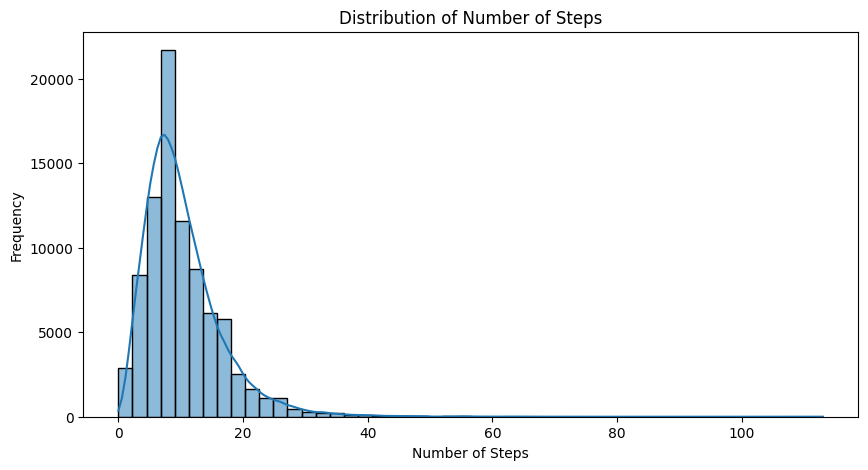

n_steps
7     7560
8     7275
6     6896
9     6862
10    6175
5     6088
11    5409
4     4798
12    4718
13    4036
Name: count, dtype: int64

In [ ]:
# Distribution of n_steps
plt.figure(figsize=(10, 5))
sns.histplot(data['n_steps'], kde=True, bins=50)
plt.title('Distribution of Number of Steps')
plt.xlabel('Number of Steps')
plt.ylabel('Frequency')
plt.show()
# Sorted frequency of n_steps
sorted_freq = data['n_steps'].value_counts().sort_values(ascending=False)
sorted_freq[:10]

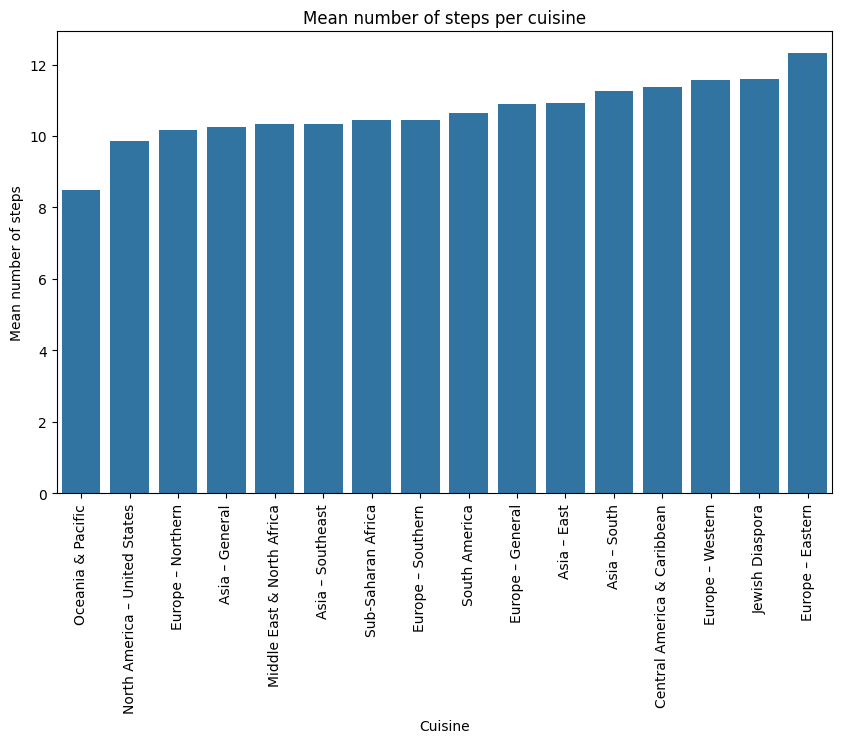

In [39]:
# Mean number of steps per cuisine
mean_steps = data.groupby('cuisine')['n_steps'].mean()
mean_steps = mean_steps.reset_index()
mean_steps.columns = ['cuisine', 'mean_steps']
# Plot the bar graph
plt.figure(figsize=(10, 6))
order = mean_steps.sort_values('mean_steps')['cuisine']
sns.barplot(x='cuisine', y='mean_steps', data=mean_steps, order=order)
plt.xticks(rotation=90)
plt.title('Mean number of steps per cuisine')
plt.xlabel('Cuisine')
plt.ylabel('Mean number of steps')
plt.show()


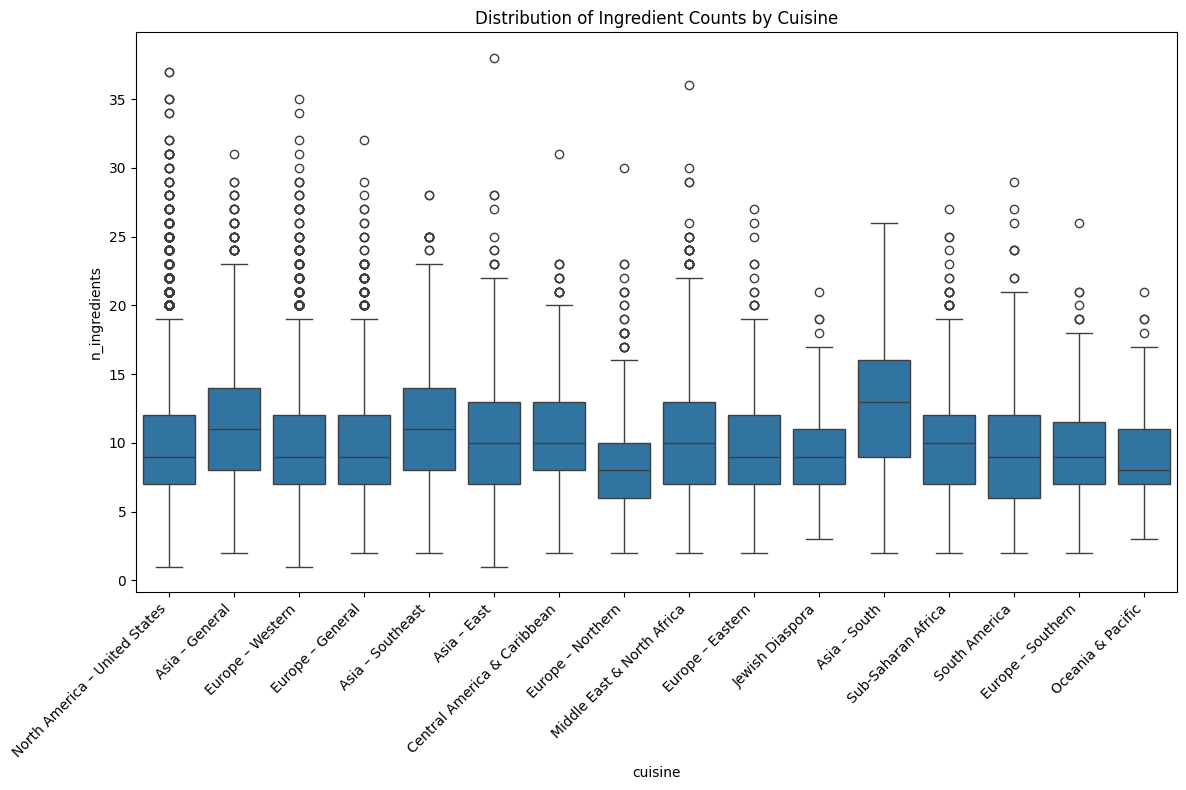

In [41]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='cuisine', y='n_ingredients', data=data)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Ingredient Counts by Cuisine')
plt.tight_layout()
plt.show()

### Conclusion

We can see that the majority of the recipes have between 6 and 10 steps. The calculated mean of number of steps is also evenly distributed across different types of cuisines but some informations can be extracted from it. We can see that the Estern European cuisine has the highest mean number of steps (12) and the Oceanic & Pacific cuisine has the lowest mean number of steps (8.5). This can be explained by the fact that Eastern European cuisine is more complex to prepare.

We can keep the number of steps as a feature in our model.

### `n_ingredients`
We will check the correlation between the number of ingredients of the recipes and the the type of cuisine of the recipe. We will also check the distribution of the number of ingredients per type of cuisine.

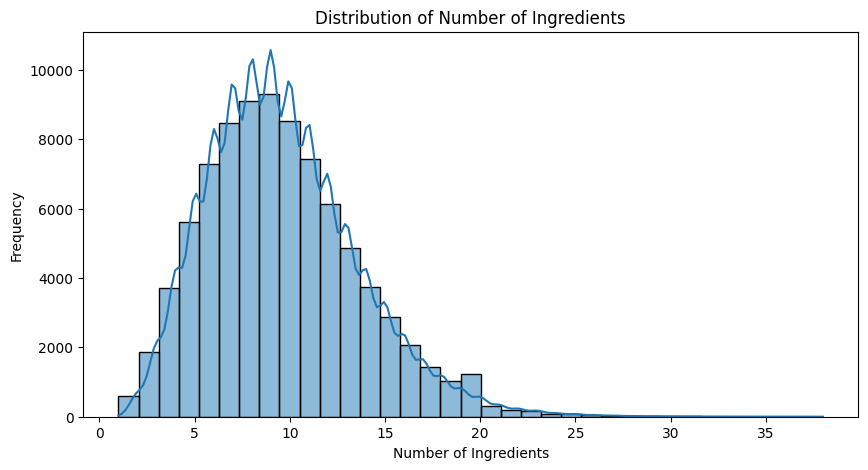

n_ingredients
9     9316
8     9096
10    8526
7     8482
11    7430
6     7285
12    6130
5     5627
13    4871
14    3733
Name: count, dtype: int64

In [34]:
# Distribution of n_ingredients
plt.figure(figsize=(10, 5))
sns.histplot(data['n_ingredients'], kde=True, bins=35)
plt.title('Distribution of Number of Ingredients')
plt.xlabel('Number of Ingredients')
plt.ylabel('Frequency')
plt.show()
# Sorted frequency of n_steps
sorted_freq = data['n_ingredients'].value_counts().sort_values(ascending=False)
sorted_freq[:10]

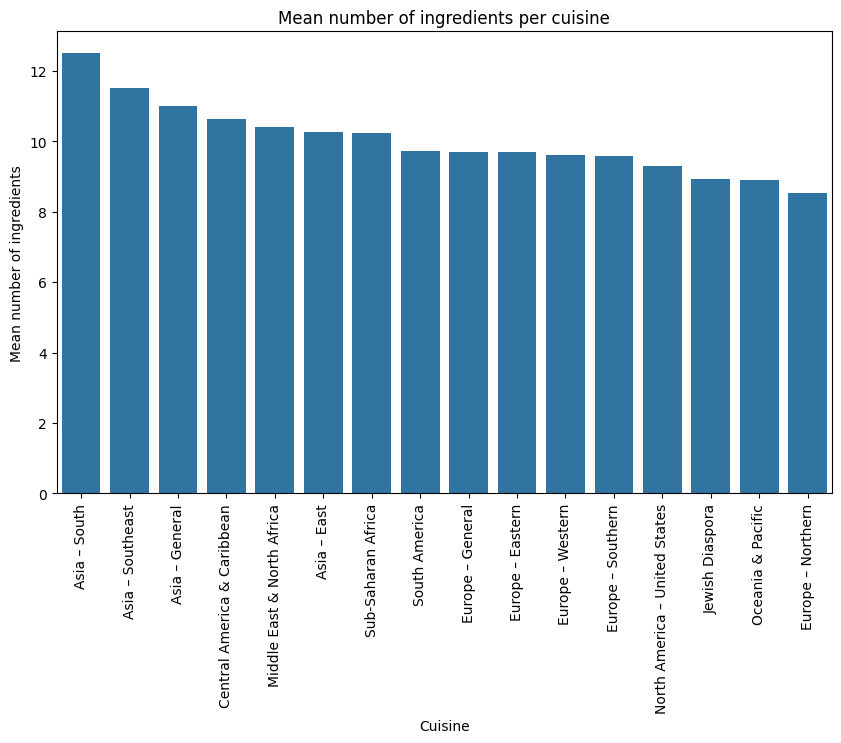

In [43]:
# Mean number of steps per cuisine
mean_ingredients = data.groupby('cuisine')['n_ingredients'].mean()
mean_ingredients = mean_ingredients.reset_index()
mean_ingredients.columns = ['cuisine', 'mean_ingredients']
mean_ingredients.sort_values('mean_ingredients', ascending=False, inplace=True)

# Plot the bar graph
plt.figure(figsize=(10, 6))
sns.barplot(x='cuisine', y='mean_ingredients', data=mean_ingredients)
plt.xticks(rotation=90)
plt.title('Mean number of ingredients per cuisine')
plt.xlabel('Cuisine')
plt.ylabel('Mean number of ingredients')
plt.show()

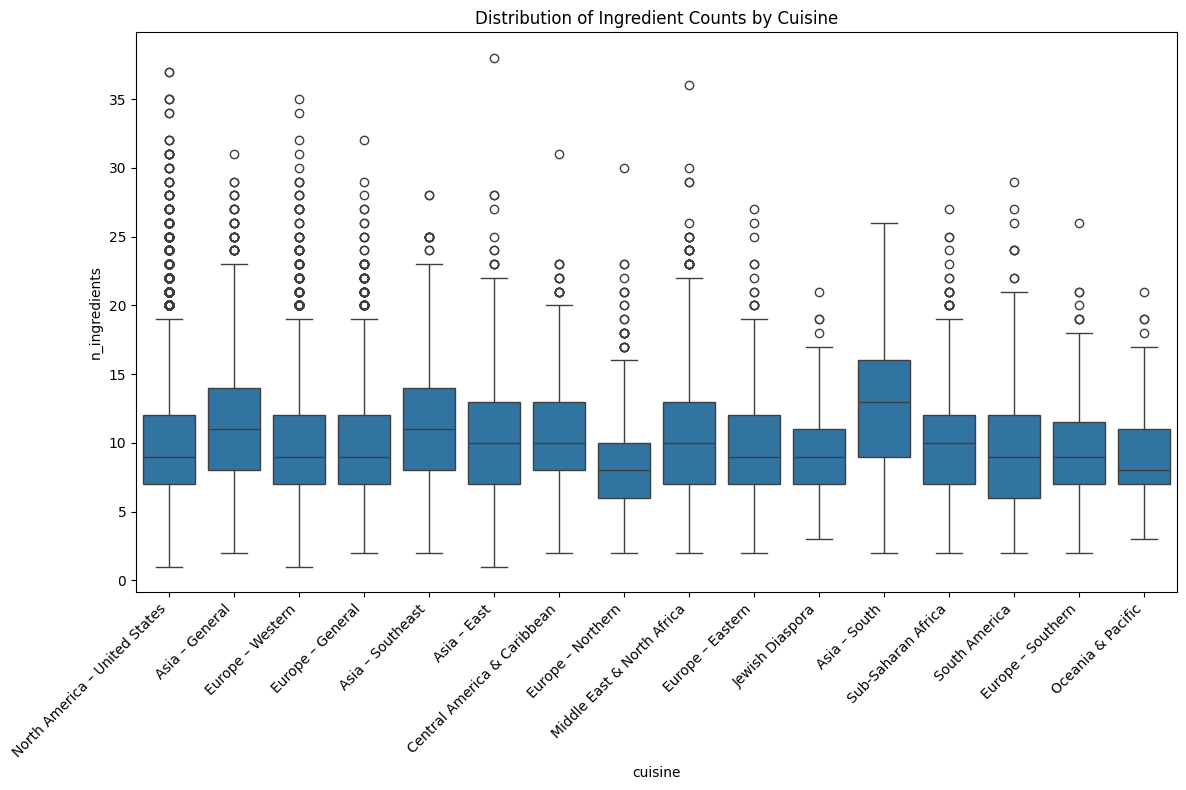

In [ ]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='cuisine', y='n_ingredients', data=data)
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Ingredient Counts by Cuisine')
plt.tight_layout()
plt.show()

### Conclusion

The number of ingredients is also evenly distributed across different types of cuisines but some informations can be extracted from it. We can see that the Southern Asian cuisine has the highest mean number of ingredients (13) and the Northern European cuisine has the lowest mean number of ingredients (9). This can be explained by the fact that Southern Asian cuisine may require more spices in their recipes.

We can keep the number of ingredients as a feature in our model as it is a good indicator of the origin of the recipe.

,cuisine,count
0,North America – United States,47868
1,Europe – General,13308
2,Asia – General,7460
3,Europe – Western,6732
4,Middle East & North Africa,2942
5,Asia – East,2842
6,Europe – Northern,914
7,Europe – Eastern,722
8,Asia – Southeast,670
9,South America,661


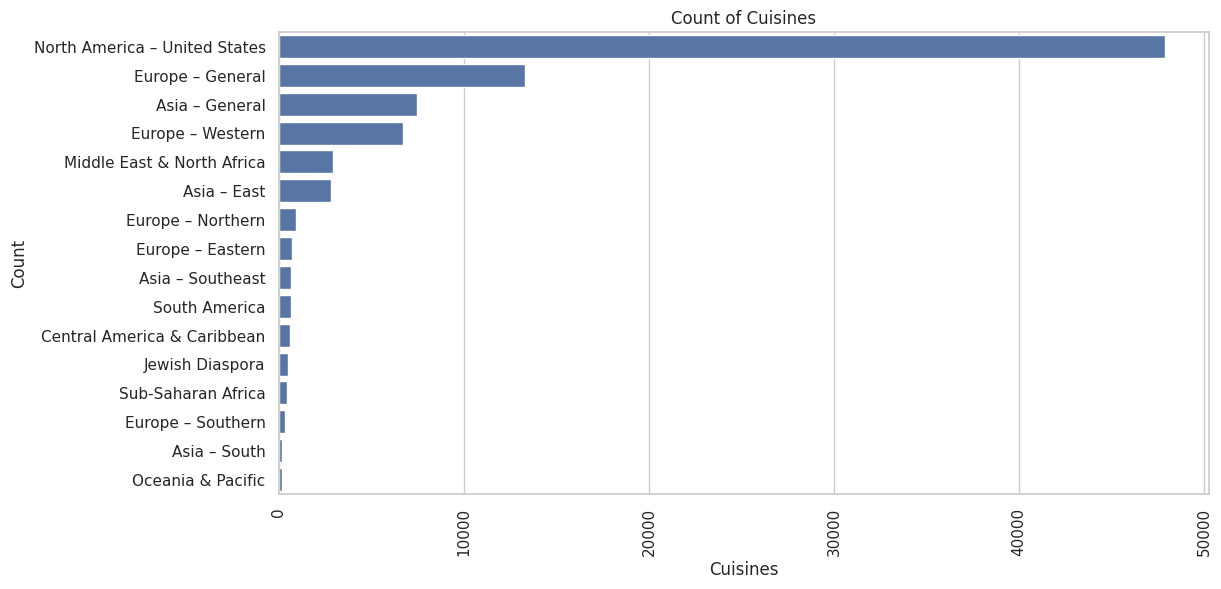

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.set(style="whitegrid")
plt.title('Count of Cuisines')
plt.xticks(rotation=90)
cuisine_counts = data['cuisine'].value_counts()
cuisine_counts = cuisine_counts.sort_values(ascending=False)
cuisine_counts = cuisine_counts.reset_index()
display(cuisine_counts)
sns.barplot(x='count', y='cuisine', data=cuisine_counts)
plt.xlabel('Cuisines')
plt.ylabel('Count')
plt.show()

The data is unbalanced as we have more recipes from the US than from other countries. We can see that the US cuisine has the highest number of recipes (~47000) and the Oc 